# Chapter 5 : Compressing Data via Dimensionality Reduction

- Feature Extraction 

- Principle Component Analysis 

- Linear Descriminant analysis 

- A brief overview of nonlinear dimensionality reduction techniques and t-distributed stochastic 
    neighbor embedding for data visualization

### Unsupervised dimensionality reduction via principal component analysis

-  PCA helps us to identify patterns in data based on the correlation between features. 

-  PCA aims to find the directions of maximum variance in high-dimensional data and projects the data onto 
    a new subspace with equal or fewer dimensions than the original one.

- Orthogonal axes (Principle Components) --> Direction of Maximum Variance given the features the contrain that the new feature axes are orthogonal to each other. 
 

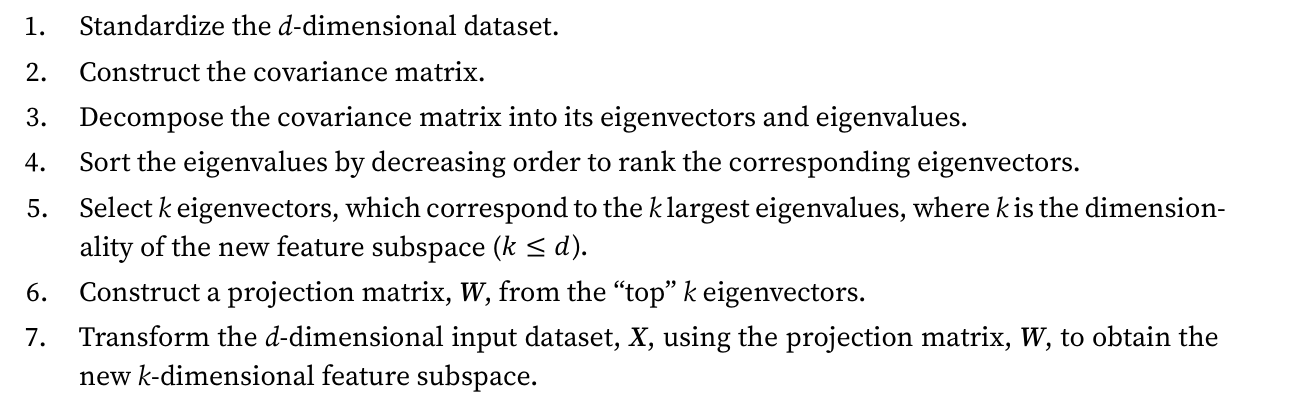

In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

In [9]:
df_wine = pd.read_csv(
    'https://archive.ics.uci.edu/ml/'
     'machine-learning-databases/wine/wine.data',
     header=None)

#### Standardize the dataset 

In [ ]:
X, y = df_wine.iloc[: , 1:].values , df_wine.iloc[:,0].values

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,stratify=y,random_state=0)

# standardize the data 
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

#### Covariance , Eiganvalues and EiganVectors 

- The covariance between two features, xj and xk, on the population level can be calculated via the following equation:

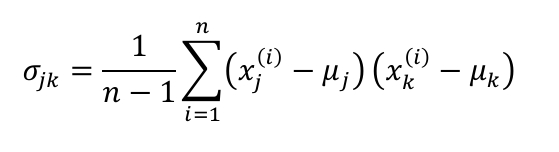

In [18]:
df_wine.shape

(178, 14)

In [19]:
cov_mat = np.cov(X_train_std.T)
print(cov_mat.shape)
print()
eigen_vals, eigen_vecs = np.linalg.eig(cov_mat)
print('\nEigenvalues \n', eigen_vals)

(13, 13)


Eigenvalues 
 [4.84274532 2.41602459 1.54845825 0.96120438 0.84166161 0.6620634
 0.51828472 0.34650377 0.3131368  0.10754642 0.21357215 0.15362835
 0.1808613 ]


In [25]:
eigen_vecs[1]

array([ 0.24724326,  0.16487119,  0.09615039,  0.56264669,  0.08953787,
        0.6270364 , -0.27400201, -0.01257758,  0.11045823,  0.02636524,
       -0.1374056 ,  0.08064016, -0.26676921])

### Total and explained variance

- The eigenvectors of the covariance matrix represent the principal components (the directions of maximum variance)

- eigenvalues will define their magnitude

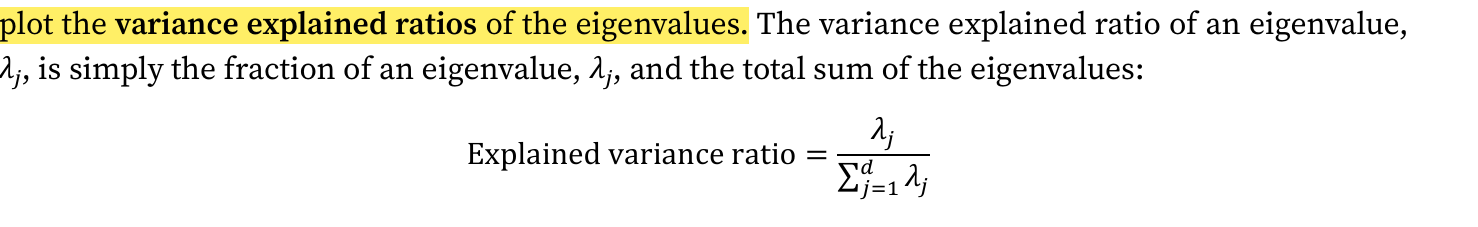

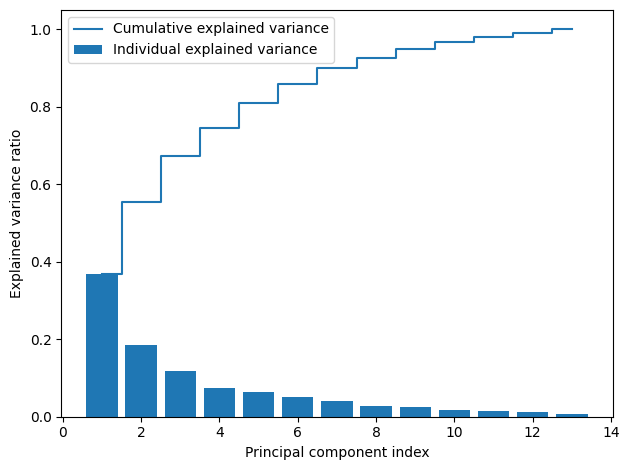

In [27]:
tot = sum(eigen_vals)

var_exp = [(i/tot) for i in sorted(eigen_vals , reverse= True)]

cum_var_exp = np.cumsum(var_exp)

plt.bar(range(1,14), var_exp, align='center',
label='Individual explained variance')
plt.step(range(1,14), cum_var_exp, where='mid',
label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#### Feature Transformation 
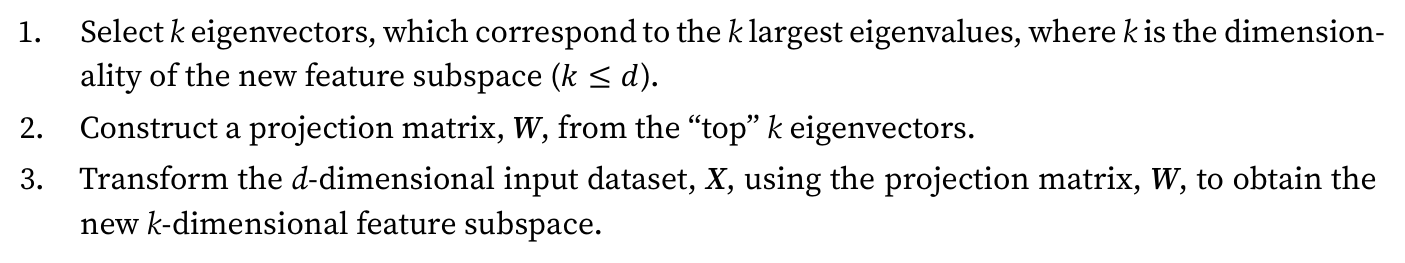

In [ ]:
eigen_pairs = [(np.abs(eigen_vals[i]) , eigen_vecs[:,i])     for i in range(len(eigen_vals))]

eigen_pairs.sort(key = lambda k: k[0] , reverse=True)

In [29]:
w = np.hstack((eigen_pairs[0][1][:, np.newaxis],eigen_pairs[1][1][:, np.newaxis]))
print('Matrix W:\n', w)

Matrix W:
 [[-0.13724218  0.50303478]
 [ 0.24724326  0.16487119]
 [-0.02545159  0.24456476]
 [ 0.20694508 -0.11352904]
 [-0.15436582  0.28974518]
 [-0.39376952  0.05080104]
 [-0.41735106 -0.02287338]
 [ 0.30572896  0.09048885]
 [-0.30668347  0.00835233]
 [ 0.07554066  0.54977581]
 [-0.32613263 -0.20716433]
 [-0.36861022 -0.24902536]
 [-0.29669651  0.38022942]]


In [32]:
w.shape

(13, 2)

In [31]:
X_train_std.shape 

(124, 13)

In [30]:
# We are taking one example x and transforming it to x' via our transformation matrix 

X_train_std[0].dot(w)

array([2.38299011, 0.45458499])

In [34]:
X_train_pca = X_train_std.dot(w)

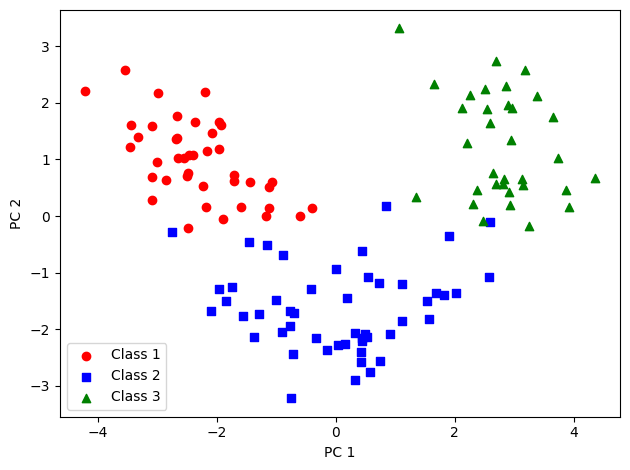

In [35]:
colors = ['r', 'b', 'g']
markers = ['o', 's', '^']
for l, c, m in zip(np.unique(y_train), colors, markers):
    plt.scatter(X_train_pca[y_train==l, 0],
                 X_train_pca[y_train==l, 1],
                 c=c, label=f'Class {l}', marker=m)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [36]:
 from matplotlib.colors import ListedColormap
 def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):
    # setup marker generator and color map
    markers = ('o', 's', '^', 'v', '<')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])
    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    lab = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    lab = lab.reshape(xx1.shape)
    plt.contourf(xx1, xx2, lab, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
    # plot class examples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=f'Class {cl}',
                    edgecolor='black')


c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


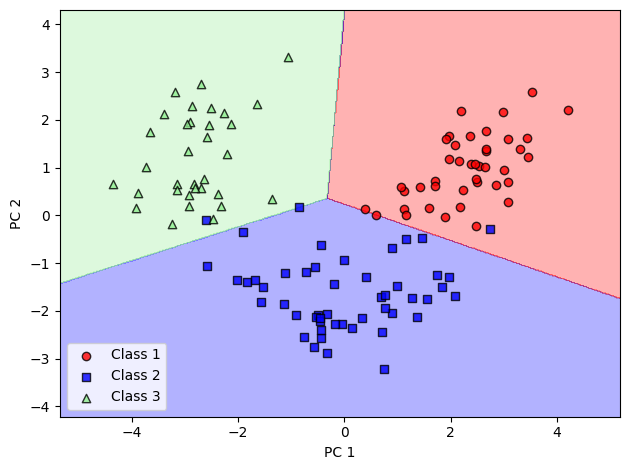

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA 

pca = PCA(n_components=2)

lr = LogisticRegression(multi_class='ovr' , random_state=1, solver = "lbfgs")

# dimensionality reduction:
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)
 # fitting the logistic regression model on the reduced dataset:
lr.fit(X_train_pca, y_train)
plot_decision_regions(X_train_pca, y_train, classifier=lr)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

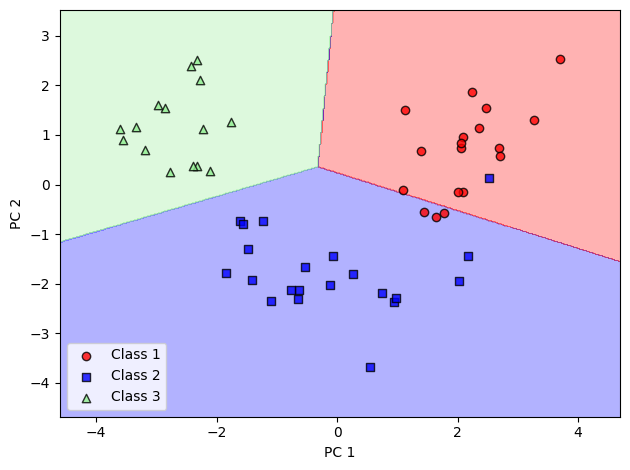

In [38]:
plot_decision_regions(X_test_pca, y_test, classifier=lr)
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [40]:
pca = PCA(n_components=None)

X_train_pca = pca.fit_transform(X_test_std)
pca.explained_variance_ratio_

array([0.36251814, 0.22827027, 0.10328402, 0.07377258, 0.06177086,
       0.04183216, 0.0396182 , 0.02772987, 0.0207188 , 0.01625372,
       0.01012088, 0.00873431, 0.00537619])

-  we are interested to know about how much each original feature contributes to a given principal component. These contributions are often called loadings.

- The factor loadings can be computed by scaling the eigenvectors by the square root of the eigenvalues.


- loadings = eigen_vecs * np.sqrt(eigen_vals)

In [43]:
loadings = eigen_vecs * np.sqrt(eigen_vals)
loadings[1]

array([ 0.54408942,  0.25626863,  0.11964672,  0.55162462,  0.08214394,
        0.51020245, -0.19725951, -0.00740374,  0.06181091,  0.00864629,
       -0.06350044,  0.03160727, -0.11345105])

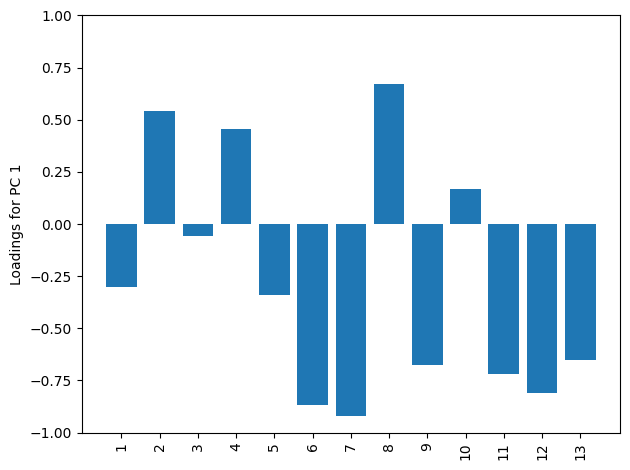

In [44]:
fig, ax = plt.subplots()
ax.bar(range(13), loadings[:, 0], align='center')
ax.set_ylabel('Loadings for PC 1')
ax.set_xticks(range(13))
ax.set_xticklabels(df_wine.columns[1:], rotation=90)
plt.ylim([-1, 1])
plt.tight_layout()
plt.show()

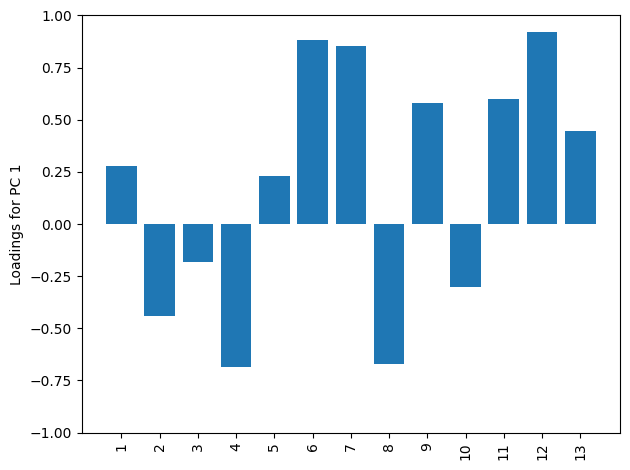

In [45]:
sklearn_loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig, ax = plt.subplots()
ax.bar(range(13), sklearn_loadings[:, 0], align='center')
ax.set_ylabel('Loadings for PC 1')
ax.set_xticks(range(13))
ax.set_xticklabels(df_wine.columns[1:], rotation=90)
plt.ylim([-1, 1])
plt.tight_layout()
plt.show()

###  Supervised data compression via linear discriminant analysis

- The goal in LDA is to find the feature subspace that optimizes class separability.

- One assumption in LDA is that the data is normally distributed.  the classes have 
    identical covariance matrices and that the training examples are statistically independent of each oth
    er.

- 

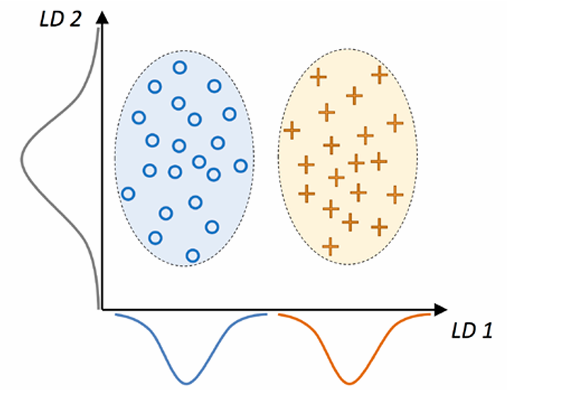

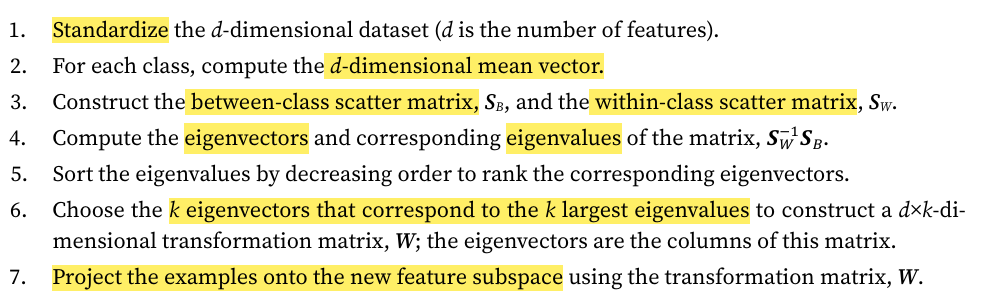

In [47]:
np.set_printoptions(precision=4)

mean_vecs = []

for label in range(1,4): 
    mean_vecs.append(np.mean(X_train_std[y_train == label] , axis = 0))
    print(f"MV {label} : {mean_vecs[label - 1 ]}\n")

MV 1 : [ 0.9066 -0.3497  0.3201 -0.7189  0.5056  0.8807  0.9589 -0.5516  0.5416
  0.2338  0.5897  0.6563  1.2075]

MV 2 : [-0.8749 -0.2848 -0.3735  0.3157 -0.3848 -0.0433  0.0635 -0.0946  0.0703
 -0.8286  0.3144  0.3608 -0.7253]

MV 3 : [ 0.1992  0.866   0.1682  0.4148 -0.0451 -1.0286 -1.2876  0.8287 -0.7795
  0.9649 -1.209  -1.3622 -0.4013]



In [50]:
d =13 #Number of features 

S_W = np.zeros((d,d))

for label , mv in zip(range(1,4) , mean_vecs):
    class_scatter = np.zeros((d,d))
    for row in X_train_std[y_train == label]:
        row, mv = row.reshape(d,1),mv.reshape(d,1)
        class_scatter += (row - mv).dot((row - mv).T)
    S_W  += class_scatter

print('Within-class scatter matrix: '
       f'{S_W.shape[0]}x{S_W.shape[1]}')

Within-class scatter matrix: 13x13


In [51]:
print('Class label distribution:',
       np.bincount(y_train)[1:])


Class label distribution: [41 50 33]


In [ ]:
# Scaled Version 
d = 13 # number of features
S_W = np.zeros((d, d))
for label,mv in zip(range(1, 4), mean_vecs):
      class_scatter = np.cov(X_train_std[y_train==label].T)
      S_W += class_scatter
print('Scaled within-class scatter matrix: '
        f'{S_W.shape[0]}x{S_W.shape[1]}')

In [56]:
mean_overall = np.mean(X_train_std, axis=0)
mean_overall = mean_overall.reshape(d, 1)
d = 13 # number of features
S_B = np.zeros((d, d))
for i, mean_vec in enumerate(mean_vecs):
      n = X_train_std[y_train == i + 1, :].shape[0]
      mean_vec = mean_vec.reshape(d, 1) # make column vector
      S_B += n * (mean_vec - mean_overall).dot(
     (mean_vec - mean_overall).T)
print('Between-class scatter matrix: '
        f'{S_B.shape[0]}x{S_B.shape[1]}')

Between-class scatter matrix: 13x13


#### Selecting linear discriminants for the new feature subspace

In [57]:
eigen_vals, eigen_vecs = np.linalg.eig(np.linalg.inv(S_W).dot(S_B))

eigen_pairs = [(np.abs(eigen_vals[i]), eigen_vecs[:,i]) for i in range(len(eigen_vals))]

eigen_pairs = sorted(eigen_pairs,
                key=lambda k: k[0], reverse=True)
print('Eigenvalues in descending order:\n')
for eigen_val in eigen_pairs:
      print(eigen_val[0])

Eigenvalues in descending order:

8.262493673957486
4.225659486916686
8.881784197001252e-16
7.22132840604883e-16
7.22132840604883e-16
3.810333788609803e-16
3.507816902433148e-16
3.507816902433148e-16
3.4967267072300994e-16
2.4216823010273643e-16
1.1311048792308754e-16
6.421170945831891e-17
6.421170945831891e-17


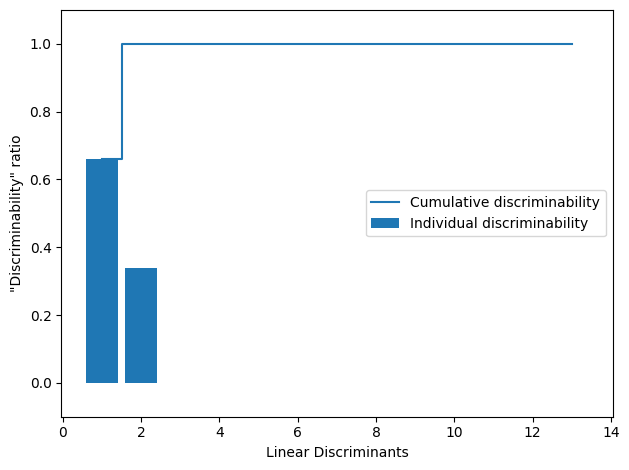

In [59]:
tot = sum(eigen_vals.real)
discr = [(i / tot) for i in sorted(eigen_vals.real,
                                    reverse=True)]
cum_discr = np.cumsum(discr)
plt.bar(range(1, 14), discr, align='center',
        label='Individual discriminability')
plt.step(range(1, 14), cum_discr, where='mid',
          label='Cumulative discriminability')
plt.ylabel('"Discriminability" ratio')
plt.xlabel('Linear Discriminants')
plt.ylim([-0.1, 1.1])
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [60]:
w = np.hstack((eigen_pairs[0][1][:, np.newaxis].real,
               eigen_pairs[1][1][:, np.newaxis].real))
print('Matrix W:\n', w)

Matrix W:
 [[-0.1586 -0.4077]
 [ 0.0984 -0.1821]
 [-0.0156 -0.3473]
 [ 0.1588  0.3095]
 [-0.0207 -0.064 ]
 [ 0.1884  0.0733]
 [-0.7153  0.3034]
 [-0.0798 -0.0009]
 [ 0.0074  0.0716]
 [ 0.3448 -0.2808]
 [-0.0254  0.244 ]
 [-0.3192 -0.0459]
 [-0.4054 -0.5806]]


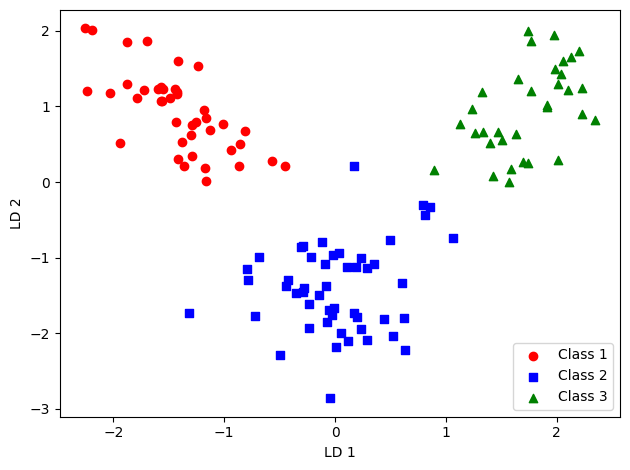

In [61]:
X_train_lda = X_train_std.dot(w)
colors = ['r', 'b', 'g']
markers = ['o', 's', '^']
for l, c, m in zip(np.unique(y_train), colors, markers):
      plt.scatter(X_train_lda[y_train==l, 0],
                  X_train_lda[y_train==l, 1] * (-1),
                  c=c, label= f'Class {l}', marker=m)
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### LDA via scikit-learn

In [63]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA 
lda = LDA(n_components=2)
X_train_lda = lda.fit_transform(X_train_std , y_train)

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


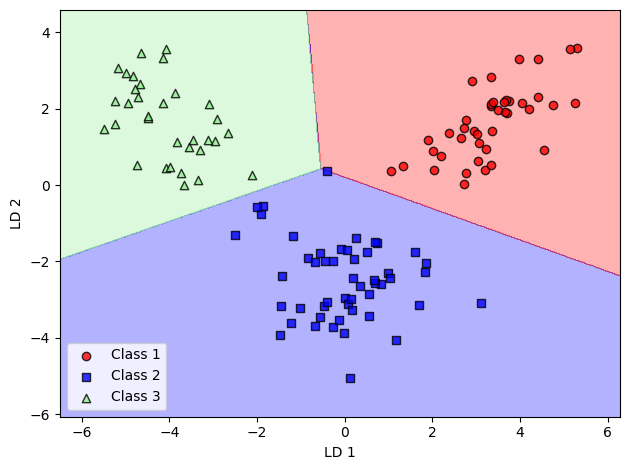

In [64]:
lr = LogisticRegression(multi_class='ovr', random_state=1,
                         solver='lbfgs')
lr = lr.fit(X_train_lda, y_train)
plot_decision_regions(X_train_lda, y_train, classifier=lr)
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

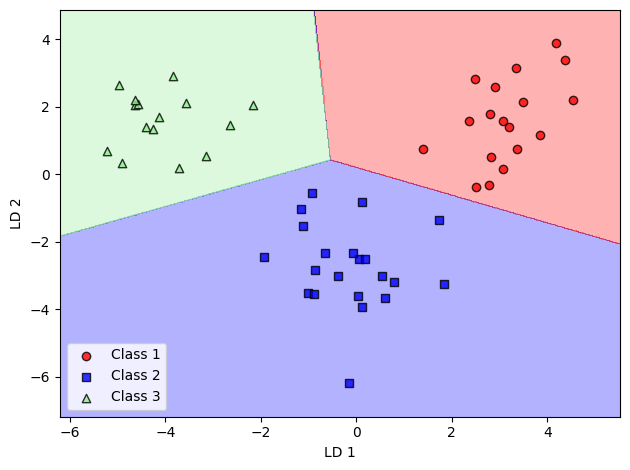

In [65]:
X_test_lda = lda.transform(X_test_std)
plot_decision_regions(X_test_lda, y_test, classifier=lr)
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

####  Nonlinear dimensionality reduction and visualization

- TSNE :  t-SNE is modeling data points based on their pair-wise distances in the high-dimen
    sional (original) feature space. Then, it finds a probability distribution of pair-wise distances in the 
    new, lower-dimensional space that is close to the probability distribution of pair-wise distances in the 
    original space. Or, in other words, t-SNE learns to embed data points into a lower-dimensional space 
    such that the pairwise distances in the original space are preserved.

- TSNE : Cannot be applied to new data points 

- Manifold Learning 

- UMAP : UMAP can produce similarly good results as t-SNE (for example, 
    see the Kobak and Linderman paper referenced previously), it is typically faster, and it 
    can also be used to project new data,

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()

<function matplotlib.pyplot.show(close=None, block=None)>

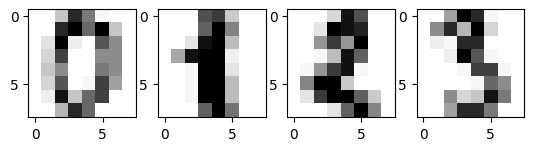

In [73]:
fig , ax = plt.subplots(1,4)

for i in range(4): 
    ax[i].imshow(digits.images[i] , cmap ="Greys")

plt.show

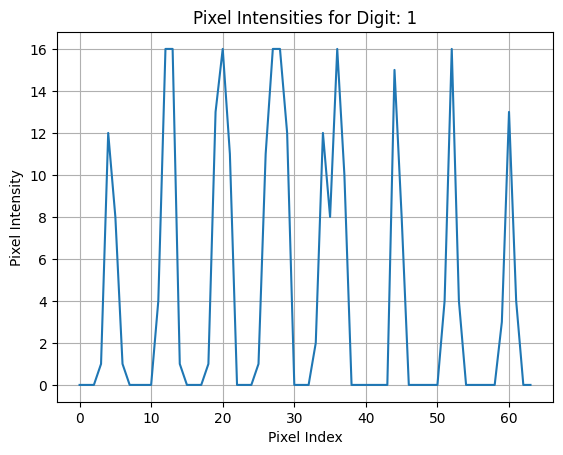

In [89]:
import torch
import torch.nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

i = 90
digits = load_digits()
name = list(digits.data[i].flatten())  # Flattened 1D array



# Plot as line plot
plt.plot(name)
plt.title(f'Pixel Intensities for Digit: {digits.target[i]}')
plt.xlabel('Pixel Index')
plt.ylabel('Pixel Intensity')
plt.grid(True)
plt.show()

In [90]:
y_digits = digits.target
X_digits = digits.data

In [93]:
from sklearn.manifold import TSNE 

# Using this code, we projected the 64-dimensional dataset onto a 2-dimensional space. We specified 
# init='pca', which initializes the t-SNE embedding using PCA as it is recommended in the research 
# article Initialization is critical for preserving global data structure in both t-SNE and UMAP by Kobak and 
# Linderman, Nature Biotechnology Volume 39, pages 156–157, 2021 (https://www.nature.com/articles/
#  s41587-020-00809-z).

tsne = TSNE(n_components=2 , init = "pca" , random_state=123)

X_digits_tsne = tsne.fit_transform(X_digits)

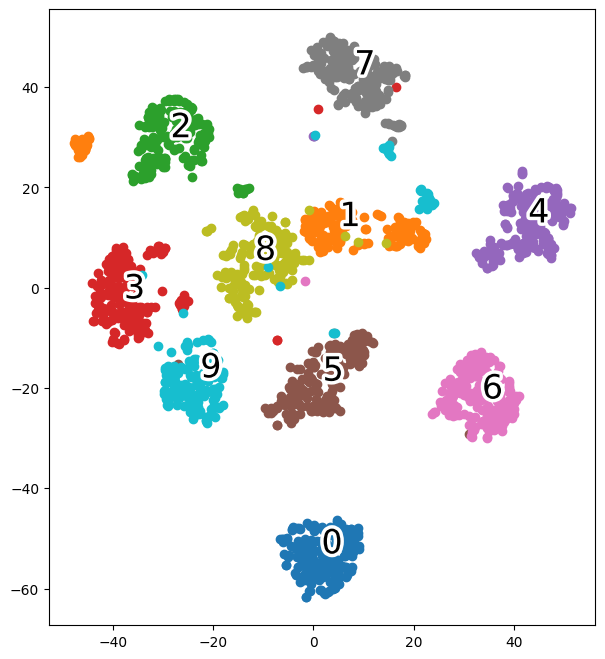

In [94]:
import matplotlib.patheffects as PathEffects

def plot_projection(x, colors):
      f = plt.figure(figsize=(8, 8))
      ax = plt.subplot(aspect='equal')
      for i in range(10):
          plt.scatter(x[colors == i, 0],
                      x[colors == i, 1])
      for i in range(10):
          xtext, ytext = np.median(x[colors == i, :], axis=0)
          txt = ax.text(xtext, ytext, str(i), fontsize=24)
          txt.set_path_effects([
              PathEffects.Stroke(linewidth=5, foreground="w"),
             PathEffects.Normal()])

plot_projection(X_digits_tsne , y_digits)
plt.show()